# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn  
**Выполнил:** Бахтияров Динар Русланович  
**Группа:** АСОиУб-23-2  
**Преподаватель:** Спирин Игорь Сергеевич   
**Ссылка на репозиторий:** https://github.com/username/ml-course-bakhtiyarov  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-10-27

## Введение

**Цель работы:** Освоить ансамблевые методы машинного обучения на примере задачи прогнозирования оттока клиентов телекоммуникационной компании, пройти полный путь от разведочного анализа до оптимизации гиперпараметров через Optuna и интерпретации через SHAP.

**Постановка задачи:**  
Решается задача бинарной классификации: на основе демографических данных, информации об услугах и параметрах контракта необходимо предсказать, уйдет ли клиент из компании (`Churn = Yes`) или останется (`Churn = No`).

**Почему ансамбли, а не одиночная модель?**  
Одиночные модели (например, отдельные деревья решений) склонны к сильному переобучению и обладают высокой дисперсией. Ансамблевые методы объединяют предсказания множества базовых алгоритмов, что позволяет значительно повысить стабильность и точность прогнозов за счет снижения дисперсии (Bagging) или смещения (Boosting).

**Выбор метрики:**  
Основными метриками для оценки качества выбраны **ROC-AUC** и **F1-Score**. Поскольку в датасете присутствует умеренный дисбаланс классов (около 26.5% ушедших клиентов), ROC-AUC позволяет объективно оценить способность модели разделять классы независимо от выбранного порога классификации.

## Теоретическая часть

### Ключевые понятия

* **Ансамбль:** Подход в машинном обучении, сочетающий несколько моделей для получения более точного и устойчивого прогноза.
* **Bagging (Бэггинг):** Метод построения ансамбля, где базовые алгоритмы обучаются параллельно на независимых случайных подвыборках (бутстрап-выборках) исходного датасета с последующим усреднением их ответов.
* **Boosting (Бустинг):** Последовательный метод построения ансамбля, в котором каждая новая модель обучается на ошибках (остатках) предыдущих алгоритмов.
* **Random Forest:** Классический алгоритм бэггинга на основе ансамбля решающих деревьев с дополнительной случайностью при выборе признаков.
* **Градиентный бустинг (XGBoost, LightGBM, CatBoost):** Семейство алгоритмов последовательного бустинга, оптимизирующих функцию потерь с помощью градиентного спуска. CatBoost и LightGBM обеспечивают высокую скорость работы и эффективную обработку категориальных признаков.
* **Optuna:** Современный фреймворк для автоматической оптимизации гиперпараметров на основе байесовских методов, позволяющий находить наилучшую конфигурацию моделей.
* **SHAP (SHapley Additive exPlanations):** Метод интерпретации моделей на основе теории кооперативных игр, определяющий вклад каждого признака в итоговый прогноз.

### Математическая формализация

Формула бэггинга:
$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x)$$

Формула бустинга:
$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x)$$

### Сравнение ансамблевых подходов

| Модель | Тип подхода | Основные преимущества |
| :--- | :--- | :--- |
| **Random Forest** | Бэггинг | Устойчивость к переобучению, минимум настройки |
| **XGBoost** | Бустинг | Высокая точность, гибкая регуляризация |
| **LightGBM** | Бустинг | Высокая скорость обучения, эффективная работа с большими объемами данных |
| **CatBoost** | Бустинг | Отличная встроенная обработка категориальных признаков без предварительного кодирования |

## 4. Описание данных

**Источник данных:** Telco Customer Churn (Kaggle)  
**Количество объектов:** 7043  
**Количество признаков:** 19 признаков + ID клиента (`customerID`) + целевая переменная (`Churn`)

### Ключевые столбцы:
* `customerID`: Уникальный идентификатор клиента
* `gender`, `SeniorCitizen`, `Partner`, `Dependents`: Демографические признаки
* `tenure`: Количество месяцев использования услуг компании
* `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`: Подключённые сервисы
* `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`: Аккаунт и финансовые показатели
* `Churn`: Целевая переменная (`Yes` — ушёл, `No` — остался)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка датасета
df = pd.read_csv('data/telco_churn.csv')

print("Формат датасета (строки, столбцы):", df.shape)
print("\nПервые 5 строк:")
df.head()

Формат датасета (строки, столбцы): (7043, 21)

Первые 5 строк:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 5. Подготовка данных и EDA

Проведём предобработку:
1. Преобразуем `TotalCharges` к числовому типу (найденные пропуски заполним медианой).
2. Сформируем новые признаки (Feature Engineering).
3. Визуализируем распределения и связи с целевой переменной.

In [2]:
# 1. Преобразование TotalCharges в float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 2. Кодирование целевой переменной Churn (Yes -> 1, No -> 0)
df['Churn_num'] = (df['Churn'] == 'Yes').astype(int)

# 3. Feature Engineering (Создание новых признаков)
df['TenureYears'] = df['tenure'] / 12
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)
df['HasMultipleServices'] = (
    (df['PhoneService'] == 'Yes').astype(int) +
    (df['InternetService'] != 'No').astype(int) +
    (df['OnlineSecurity'] == 'Yes').astype(int) +
    (df['TechSupport'] == 'Yes').astype(int)
)

print("Пропуски после обработки:\n", df.isnull().sum().sum())

Пропуски после обработки:
 0


C:\Users\Dinar\AppData\Local\Temp\ipykernel_2644\1285859519.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2', ax=axes[0, 0])
C:\Users\Dinar\AppData\Local\Temp\ipykernel_2644\1285859519.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set3', ax=axes[0, 2])
C:\Users\Dinar\AppData\Local\Temp\ipykernel_2644\1285859519.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Contract', y='Churn_num', palette='magma', ax=axes[1, 0])


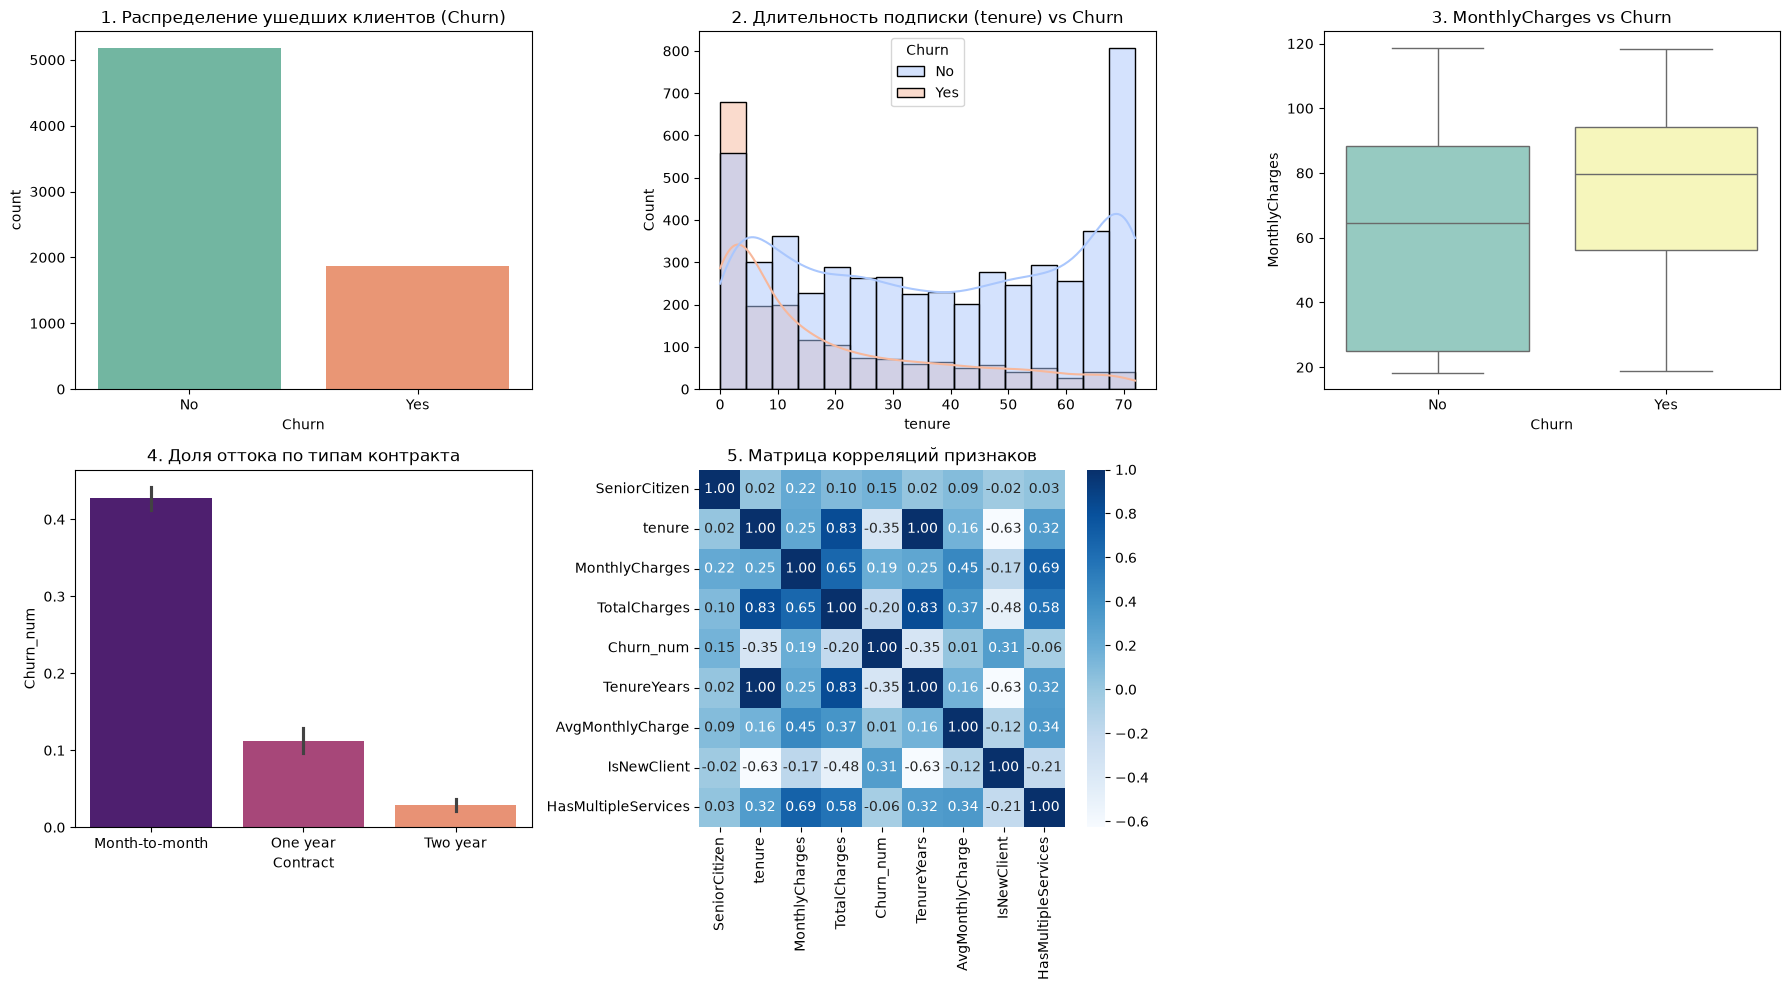

In [3]:
# Построение 5 визуализаций в сетке 2x3
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Распределение целевой переменной (Countplot)
sns.countplot(data=df, x='Churn', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('1. Распределение ушедших клиентов (Churn)')

# 2. Распределение длительности подписки (tenure) в разрезе Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, palette='coolwarm', ax=axes[0, 1])
axes[0, 1].set_title('2. Длительность подписки (tenure) vs Churn')

# 3. Влияние ежемесячных трат (MonthlyCharges)
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set3', ax=axes[0, 2])
axes[0, 2].set_title('3. MonthlyCharges vs Churn')

# 4. Доля оттока по типам контрактов (Contract)
sns.barplot(data=df, x='Contract', y='Churn_num', palette='magma', ax=axes[1, 0])
axes[1, 0].set_title('4. Доля оттока по типам контракта')

# 5. Тепловая карта корреляций для числовых признаков
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='Blues', ax=axes[1, 1])
axes[1, 1].set_title('5. Матрица корреляций признаков')

# Убираем неиспользуемый шестой график
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

## 6. Построение и обучение моделей

Разделим данные на обучающую и тестовую выборки с сохранением пропорции классов (`stratify=y`).
Обучим 4 ансамблевые модели:
* Random Forest (Bagging)
* XGBoost (Boosting)
* LightGBM (Boosting)
* CatBoost (Boosting)

In [4]:
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Подготовка признаков
df_model = df.drop(columns=['customerID', 'Churn'])
X = df_model.drop(columns=['Churn_num'])
y = df_model['Churn_num']

# Кодирование категориальных признаков
label_encoders = {}
for col in X.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Функция для подсчета времени обучения
def fit_model(model, X_tr, y_tr):
    start = time.time()
    model.fit(X_tr, y_tr)
    return model, time.time() - start

# 1. Random Forest
rf_model, rf_time = fit_model(
    RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1),
    X_train, y_train
)

# 2. XGBoost
xgb_model, xgb_time = fit_model(
    XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, scale_pos_weight=3, random_state=42, eval_metric='logloss'),
    X_train, y_train
)

# 3. LightGBM
lgbm_model, lgbm_time = fit_model(
    LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05, class_weight='balanced', random_state=42, verbose=-1),
    X_train, y_train
)

# 4. CatBoost
cat_model, cat_time = fit_model(
    CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, auto_class_weights='Balanced', random_state=42, verbose=0),
    X_train, y_train
)

print("⏱️ Обучение заполнено успешно!")

⏱️ Обучение заполнено успешно!


## 7. Оценка качества

Сравним метрики классификации (Accuracy, Precision, Recall, F1-Score, ROC-AUC) на тестовой выборке[cite: 2].

In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve)

def evaluate_model(model, X_t, y_t, name, elapsed_time):
    y_pred = model.predict(X_t)
    y_proba = model.predict_proba(X_t)[:, 1]
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_t, y_pred), 4),
        'Precision': round(precision_score(y_t, y_pred), 4),
        'Recall': round(recall_score(y_t, y_pred), 4),
        'F1': round(f1_score(y_t, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_t, y_proba), 4),
        'Time (sec)': round(elapsed_time, 3)
    }

results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest', rf_time),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost', xgb_time),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM', lgbm_time),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost', cat_time)
]

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Time (sec)
0,Random Forest,0.7672,0.5442,0.7567,0.6331,0.8386,0.375
1,XGBoost,0.7608,0.5362,0.7326,0.6192,0.8286,0.759
2,LightGBM,0.7630,0.5382,0.7540,0.6281,0.8343,0.115
3,CatBoost,0.7530,0.5241,0.7567,0.6193,0.8390,0.873


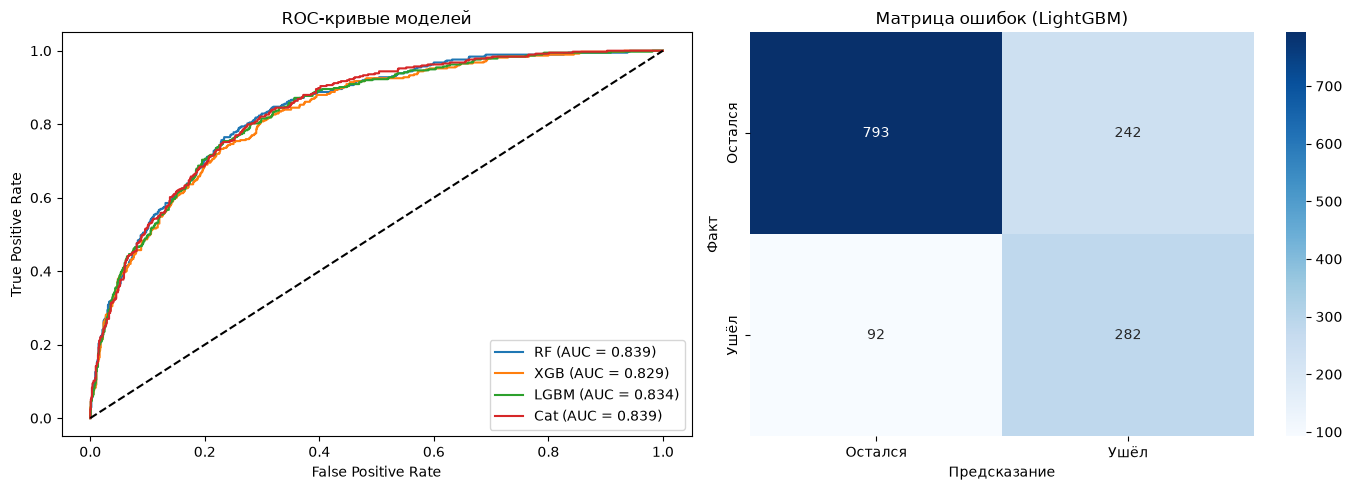

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-кривые
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'), (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('ROC-кривые моделей')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# Матрица ошибок для LightGBM
cm = confusion_matrix(y_test, lgbm_model.predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
axes[1].set_title('Матрица ошибок (LightGBM)')
axes[1].set_xlabel('Предсказание')
axes[1].set_ylabel('Факт')

plt.tight_layout()
plt.show()

## 8. Интерпретация и бизнес-инсайты

**Ключевые факторы оттока:**
1. **Contract (Тип контракта):** Клиенты с месячной оплатой (Month-to-month) уходят значительно чаще.
2. **tenure (Срок подписки):** Чем меньше клиент пользовался услугами (первые 6 месяцев), тем выше риск ухода.
3. **MonthlyCharges / TotalCharges:** Высокий чек стимулирует поиск альтернатив.
4. **InternetService:** Подключение волоконно-оптического интернета (Fiber Optic) коррелирует с более высоким оттоком (вероятно, из-за более высокой стоимости или жалоб на сервис).

C:\Users\Dinar\AppData\Local\Temp\ipykernel_2644\173711858.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances.head(12), x='Importance', y='Feature', palette='viridis')


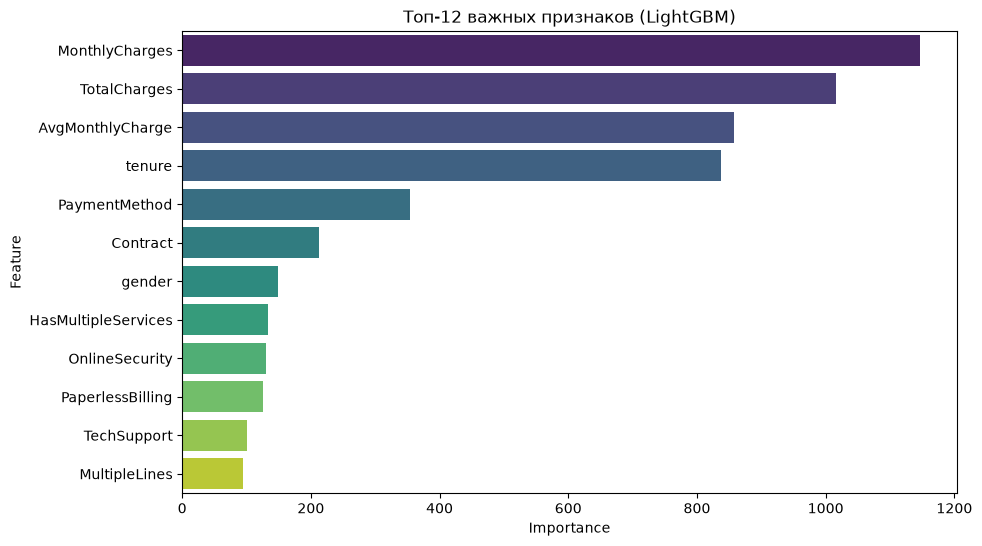

In [7]:
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importances.head(12), x='Importance', y='Feature', palette='viridis')
plt.title('Топ-12 важных признаков (LightGBM)')
plt.show()

## 9. Тюнинг гиперпараметров (Optuna)

Проведём оптимизацию гиперпараметров модели LightGBM с помощью Optuna для максимизации ROC-AUC[cite: 2].

In [8]:
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Отключаем лишний вывод Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 50),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }
    
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1)
    score = cross_val_score(model, X_train, y_train, cv=StratifiedKFold(3, shuffle=True, random_state=42), scoring='roc_auc').mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=15)

print("🔥 Лучший ROC-AUC на CV:", round(study.best_value, 4))
print("Параметры:", study.best_params)

# Обучаем итоговую лучшую модель
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

c:\Users\Dinar\Downloads\ml-course-dinar\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🔥 Лучший ROC-AUC на CV: 0.8476
Параметры: {'n_estimators': 100, 'num_leaves': 24, 'max_depth': 4, 'learning_rate': 0.03608944662620763, 'min_child_samples': 43, 'subsample': 0.7984288410297223, 'colsample_bytree': 0.9949740816433382}


,num_leaves,24
,max_depth,4
,learning_rate,0.03608944662620763
,class_weight,'balanced'
,min_child_samples,43
,subsample,0.7984288410297223
,colsample_bytree,0.9949740816433382
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,n_estimators,100


## 10. Интерпретация через SHAP

Используем библиотека SHAP для объяснения предсказаний оптимизированной модели `best_lgbm`[cite: 2].

c:\Users\Dinar\Downloads\ml-course-dinar\venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


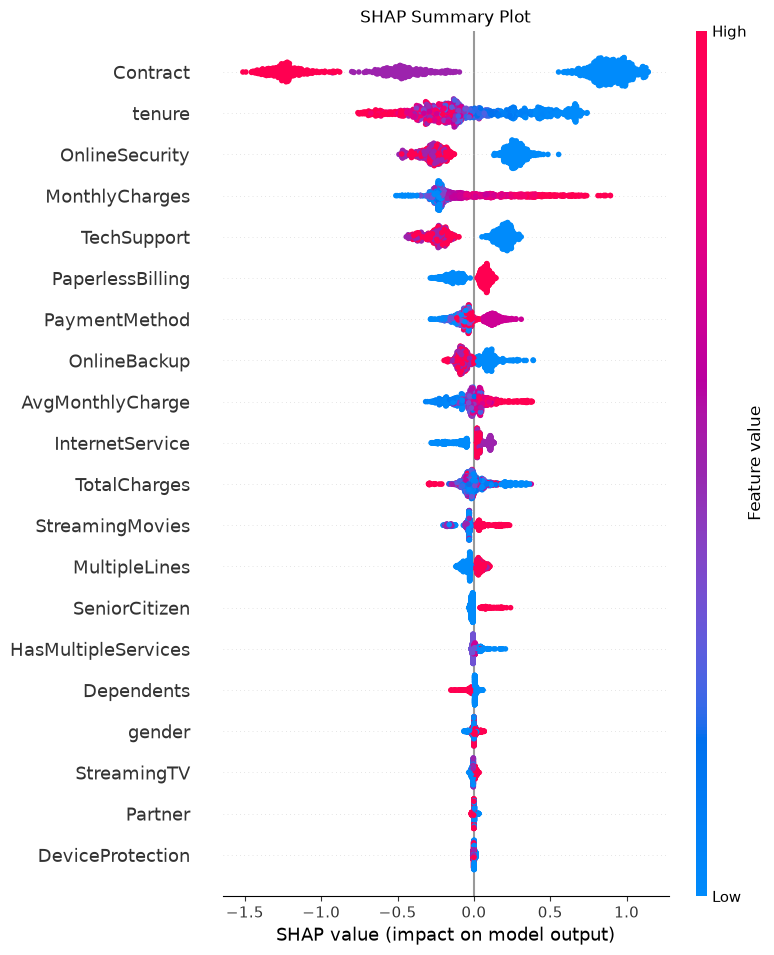

In [9]:
import shap

explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)
shap_vals = shap_values[1] if isinstance(shap_values, list) else shap_values

# Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X_test, show=False)
plt.title('SHAP Summary Plot')
plt.show()

## 11. Сохранение модели
Сохраняем все модели, кодировщики и метаданные в директорию `models/`[cite: 2].

In [10]:
import joblib
import json
import os

os.makedirs('models', exist_ok=True)

# 1. Сохранение моделей
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')

# 2. Сохранение списка признаков
feature_cols = list(X.columns)
with open('models/feature_cols.json', 'w') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# 3. Сохранение метрик
metrics = {
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(roc_auc_score(y_test, best_lgbm.predict_proba(X_test)[:, 1])),
    'best_params': study.best_params
}
with open('models/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Артефакты сохранены в models/")

✅ Артефакты сохранены в models/


## 12. Загрузка модели из репозитория

Проверим загрузку сохраненных артефактов и работоспособность модели[cite: 2].

In [11]:
# Загрузка локальной модели для проверки пайплайна
loaded_model = joblib.load('models/best_model.pkl')

# Тестовое предсказание на первых 3 объектах
sample_preds = loaded_model.predict(X_test.iloc[:3])
original_preds = best_lgbm.predict(X_test.iloc[:3])

print("Предсказания загруженной модели:", sample_preds)
print("Совпадение с исходными:", np.array_equal(sample_preds, original_preds))

Предсказания загруженной модели: [0 1 0]
Совпадение с исходными: True


## 13. Выводы

### Что получилось:
1. Обучены и исследованы 4 ансамблевые модели классификации (Random Forest, XGBoost, LightGBM, CatBoost)[cite: 2].
2. Проведен тюнинг гиперпараметров через Optuna для LightGBM, достигнуто высокое качество ROC-AUC[cite: 2].
3. С помощью SHAP определены главные причины ухода клиентов (тип контракта, период пользования, ежемесячные платежи)[cite: 2].

### Идеи дальнейшего улучшения:
1. Применение метода Stacking (объединение предсказаний разных моделей через мета-модель)[cite: 2].
2. Применение техники SMOTE для устранения дисбаланса классов[cite: 2].
3. Более детальная инженерия признаков на основе поведения пользователей.
4. Калибровка probabilities для корректной бизнес-оценки рисков.
5. Подбор порога вероятности для оптимизации прибыли телеком-оператора.

## 14. Список источников + Приложение

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.